# 🔢 Notebook 3: Word Embeddings - Rappresentare le Parole come Numeri

**Trasformiamo le parole in vettori!** 🧮

## 🎯 Obiettivi di questo notebook:
- Comprendere perché l'AI ha bisogno di numeri
- Implementare Bag of Words (BoW)
- Calcolare TF-IDF da zero
- Esplorare Word2Vec pre-addestrato
- Visualizzare embeddings con t-SNE
- Confrontare diversi metodi di rappresentazione
- Applicare embeddings a problemi reali

## ⏱️ Tempo stimato: 75-90 minuti

## 📋 Prerequisiti: 
- Notebook 1 e 2 completati
- Concetti base di algebra lineare (vettori, distanze)
- Familiarità con la pre-elaborazione del testo

In [1]:
# Installiamo le librerie necessarie
!pip install gensim scikit-learn matplotlib seaborn pandas numpy nltk spacy wordcloud plotly
!pip install umap-learn  # Per visualizzazioni alternative


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Invalid requirement: '#'

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 🔧 Setup e Installazione

Installiamo le librerie necessarie per lavorare con gli embeddings:

In [2]:

# Importiamo le librerie
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter, defaultdict
import re
import math

# Librerie per NLP
import nltk
# import spacy
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Librerie per embeddings
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import gensim
from gensim.models import Word2Vec
from gensim.models.keyedvectors import KeyedVectors

# Visualizzazioni
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go

# Download dati NLTK
nltk.download('punkt')
nltk.download('stopwords')

# Configurazione grafica
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 8)

print("✅ Setup completato! Pronti per esplorare i Word Embeddings.")

c:\Users\A1618apulia\OneDrive - ITS Apulia Digital Maker\Desktop\GENERATIVEAI\.venv\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.7.0) or chardet (6.0.0.post1)/charset_normalizer (3.5.1) doesn't match a supported version!
  warnings.warn(


✅ Setup completato! Pronti per esplorare i Word Embeddings.


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\A1618apulia\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\A1618apulia\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## 🤔 Perché l'AI Ha Bisogno di Numeri?

I computer non capiscono le parole, ma solo numeri. Vediamo il problema:

🤖 IL PROBLEMA: Come fa un computer a capire le parole?

📝 PAROLE UMANE:
   1. gatto
   2. cane
   3. automobile
   4. felice
   5. triste

🔢 RAPPRESENTAZIONE COMPUTER (ASCII):
   1. gatto → [103, 97, 116, 116, 111]
   2. cane → [99, 97, 110, 101]
   3. automobile → [97, 117, 116, 111, 109, 111, 98, 105, 108, 101]
   4. felice → [102, 101, 108, 105, 99, 101]
   5. triste → [116, 114, 105, 115, 116, 101]

❌ PROBLEMI CON ASCII:
   • Lunghezze diverse
   • Nessuna relazione semantica
   • 'gatto' e 'cane' sembrano completamente diversi
   • Non cattura il significato


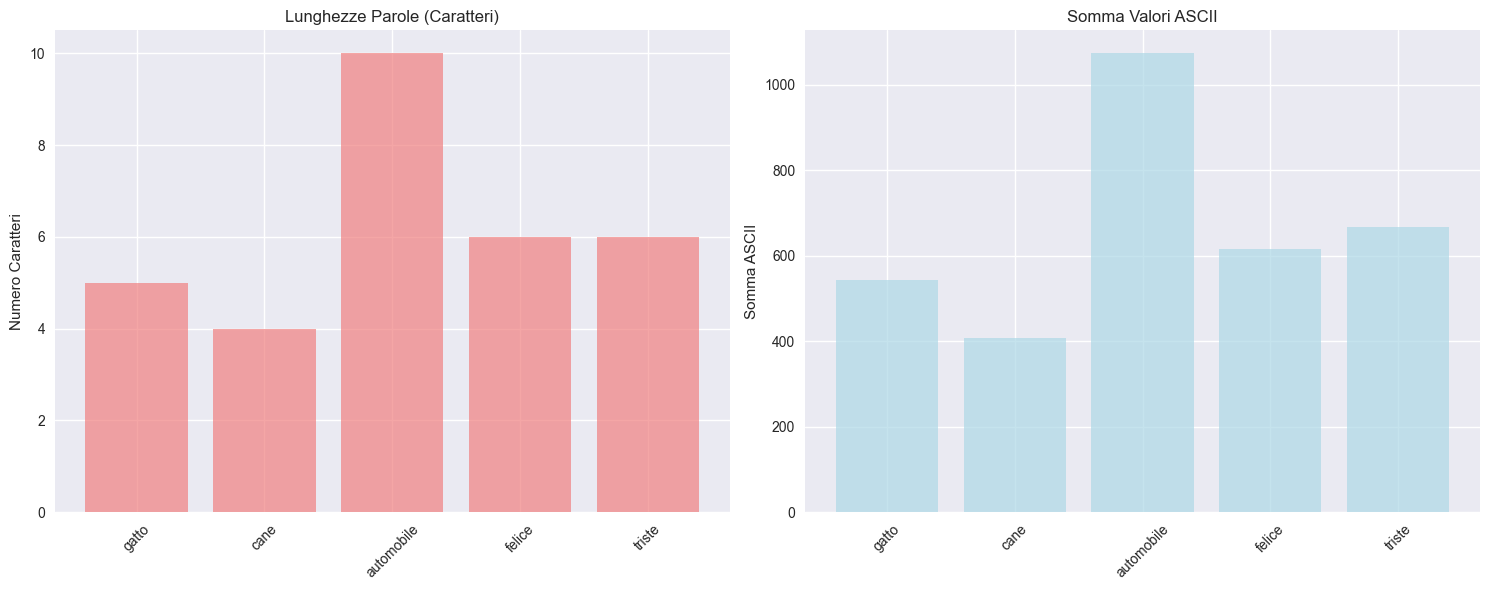


💡 SOLUZIONE: Word Embeddings!
   • Rappresentano parole come vettori di numeri
   • Catturano relazioni semantiche
   • Parole simili hanno vettori simili
   • Dimensione fissa per tutte le parole

🎯 ESEMPIO CONCETTUALE (2D):


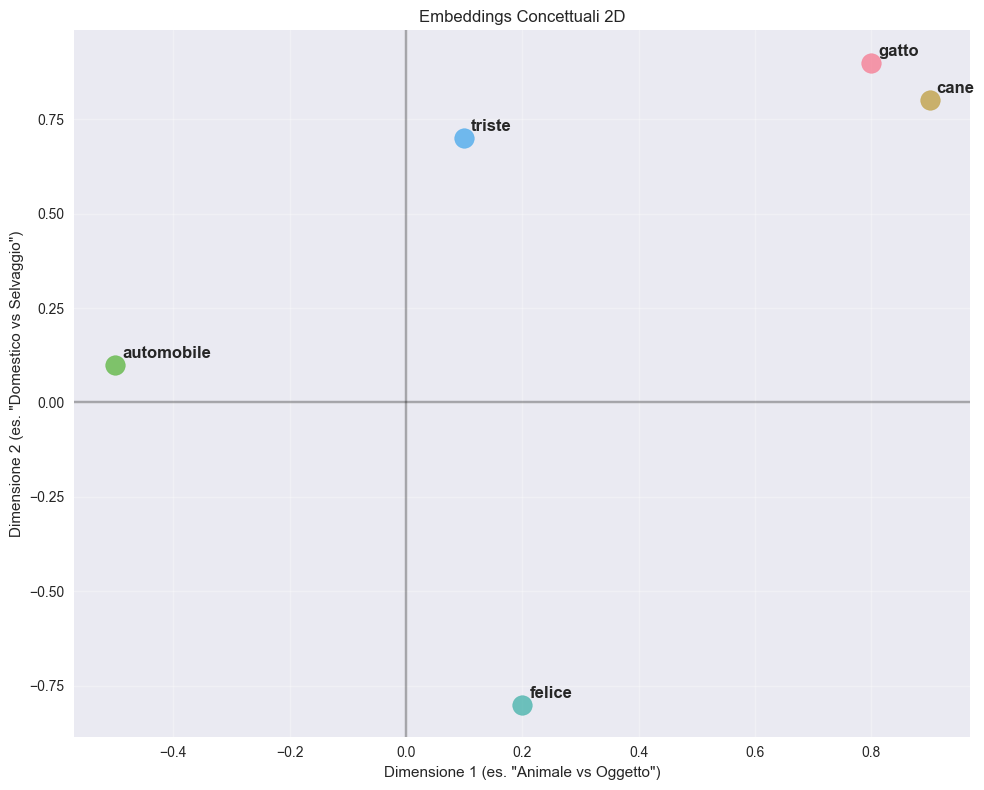

👀 OSSERVAZIONI:
   • 'gatto' e 'cane' sono vicini (entrambi animali domestici)
   • 'automobile' è lontano (oggetto meccanico)
   • 'felice' e 'triste' sono in zone diverse (emozioni opposte)


In [ ]:
# Il problema della rappresentazione
print("🤖 IL PROBLEMA: Come fa un computer a capire le parole?\n")

# Esempio di parole
parole = ["gatto", "cane", "automobile", "felice", "triste"]

print("📝 PAROLE UMANE:")
for i, parola in enumerate(parole):
    print(f"   {i+1}. {parola}")

print("\n🔢 RAPPRESENTAZIONE COMPUTER (ASCII):")
for i, parola in enumerate(parole):
    ascii_vals = [ord(char) for char in parola]
    print(f"   {i+1}. {parola} → {ascii_vals}")
# ascii è una list comprehension che converte ogni carattere in un valore numerico (ASCII)


print("\n❌ PROBLEMI CON ASCII:")
print("   • Lunghezze diverse")
print("   • Nessuna relazione semantica")
print("   • 'gatto' e 'cane' sembrano completamente diversi")
print("   • Non cattura il significato")

# Visualizziamo il problema
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Grafico 1: Lunghezze parole
lunghezze = [len(parola) for parola in parole]
ax1.bar(parole, lunghezze, color='lightcoral', alpha=0.7)
ax1.set_title('Lunghezze Parole (Caratteri)')
ax1.set_ylabel('Numero Caratteri')
ax1.tick_params(axis='x', rotation=45)


# Grafico 2: Somma valori ASCII
ascii_sums = [sum(ord(char) for char in parola) for parola in parole] 
ax2.bar(parole, ascii_sums, color='lightblue', alpha=0.7)
ax2.set_title('Somma Valori ASCII')
ax2.set_ylabel('Somma ASCII')
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print("\n💡 SOLUZIONE: Word Embeddings!")
print("   • Rappresentano parole come vettori di numeri")
print("   • Catturano relazioni semantiche")
print("   • Parole simili hanno vettori simili")
print("   • Dimensione fissa per tutte le parole")

# Esempio concettuale di embeddings
print("\n🎯 ESEMPIO CONCETTUALE (2D):")
embeddings_esempio = {
    'gatto': [0.8, 0.9],    # Animale domestico
    'cane': [0.9, 0.8],     # Animale domestico (simile a gatto)
    'automobile': [-0.5, 0.1],  # Oggetto meccanico
    'felice': [0.2, -0.8],  # Emozione positiva
    'triste': [0.1, 0.7]    # Emozione negativa
}
#il dizio0nario deve avere le parole come chiavi e un valore. In questo caso abbiamo scelto una lista di due valori per rappresentare le coordinate 2D degli embeddings concettuali.

# Visualizziamo gli embeddings concettuali
fig, ax = plt.subplots(figsize=(10, 8))

for parola, (x, y) in embeddings_esempio.items(): #serve per iterare sul dizionario 
    #embeddings_esempio, ottenendo sia la parola (chiave) che le coordinate (valore) per ciascun embedding.
    ax.scatter(x, y, s=200, alpha=0.7)
    ax.annotate(parola, (x, y), xytext=(5, 5), textcoords='offset points',
                fontsize=12, fontweight='bold') 

ax.set_xlabel('Dimensione 1 (es. "Animale vs Oggetto")')
ax.set_ylabel('Dimensione 2 (es. "Domestico vs Selvaggio")')
ax.set_title('Embeddings Concettuali 2D')
ax.grid(True, alpha=0.3)
ax.axhline(y=0, color='k', linestyle='-', alpha=0.3)
ax.axvline(x=0, color='k', linestyle='-', alpha=0.3)

plt.tight_layout()
plt.show()

print("👀 OSSERVAZIONI:")
print("   • 'gatto' e 'cane' sono vicini (entrambi animali domestici)")
print("   • 'automobile' è lontano (oggetto meccanico)")
print("   • 'felice' e 'triste' sono in zone diverse (emozioni opposte)")

## 🎒 Bag of Words (BoW) - Il Metodo Base

Iniziamo con il metodo più semplice: **Bag of Words**

🎒 BAG OF WORDS - IMPLEMENTAZIONE DA ZERO

📝 DOCUMENTI DI ESEMPIO:
   1. il gatto dorme sul divano
   2. il cane corre nel parco
   3. il gatto e il cane sono amici
   4. sul divano c'è un gatto nero
   5. nel parco corrono molti cani
📚 Vocabolario costruito: 18 parole uniche

📚 VOCABOLARIO (18 parole):
['amici', "c'è", 'cane', 'cani', 'corre', 'corrono', 'divano', 'dorme', 'e', 'gatto', 'il', 'molti', 'nel', 'nero', 'parco', 'sono', 'sul', 'un']

🔢 MATRICE BAG OF WORDS (5 documenti x 18 parole):
       amici  c'è  cane  cani  corre  corrono  divano  dorme    e  gatto   il  \
Doc 1    0.0  0.0   0.0   0.0    0.0      0.0     1.0    1.0  0.0    1.0  1.0   
Doc 2    0.0  0.0   1.0   0.0    1.0      0.0     0.0    0.0  0.0    0.0  1.0   
Doc 3    1.0  0.0   1.0   0.0    0.0      0.0     0.0    0.0  1.0    1.0  2.0   
Doc 4    0.0  1.0   0.0   0.0    0.0      0.0     1.0    0.0  0.0    1.0  0.0   
Doc 5    0.0  0.0   0.0   1.0    0.0      1.0     0.0    0.0  0.0    0.0  0.0   

       molti

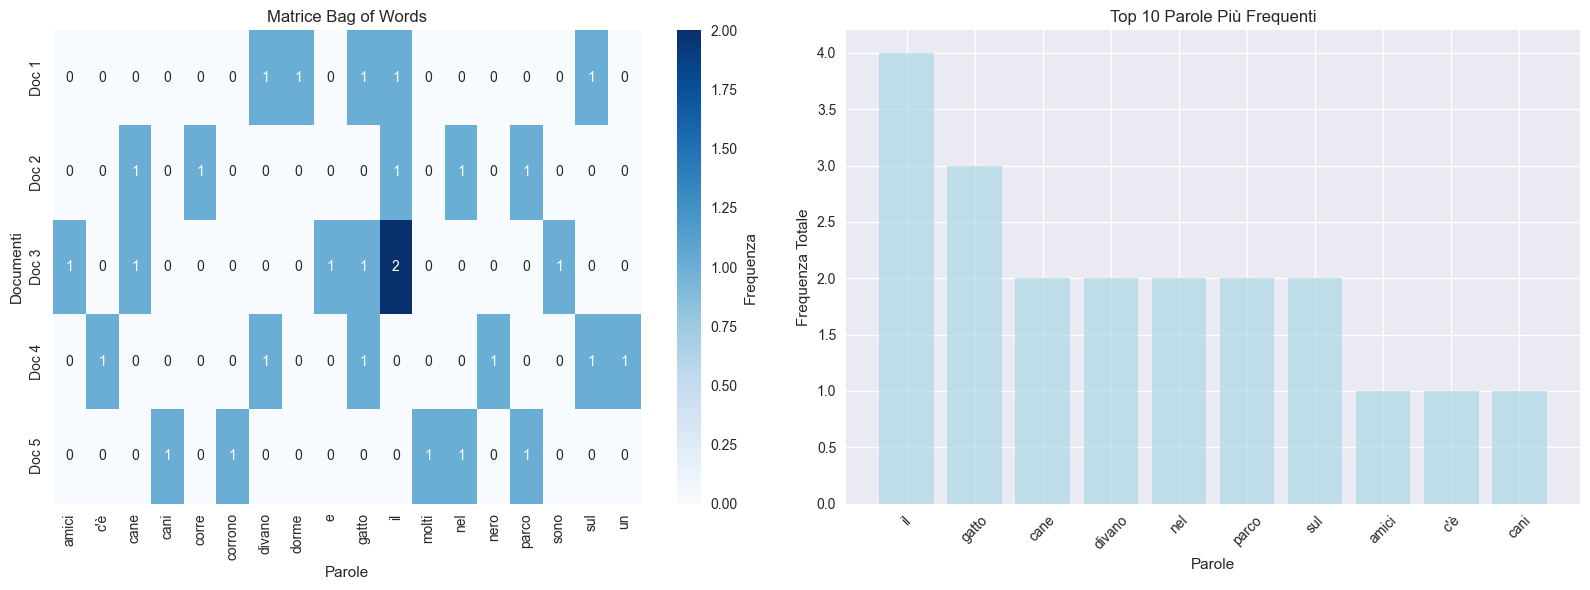


💡 CARATTERISTICHE BAG OF WORDS:
✅ Vantaggi:
   • Semplice da implementare
   • Interpretabile
   • Veloce
   • Buono per classificazione base

❌ Svantaggi:
   • Ignora l'ordine delle parole
   • Vettori molto sparsi (molti zeri)
   • Dimensionalità alta
   • Non cattura relazioni semantiche

🔍 ESEMPIO SIMILARITÀ:
Similarità Doc 1 vs Doc 3: 0.447
Similarità Doc 1 vs Doc 4: 0.548
(Doc 1 e 4 parlano entrambi di gatti sul divano)


In [4]:
# Implementiamo Bag of Words da zero
class BagOfWords:
    def __init__(self):
        self.vocabolario = {}
        self.vocabolario_inverso = {}
        self.dimensione_vocab = 0
    
    def costruisci_vocabolario(self, documenti):
        """Costruisce il vocabolario da una lista di documenti"""
        tutte_parole = set() # utilizzo il set per non avere duplicati nel risultato
        
        for doc in documenti:
            parole = doc.lower().split()
            tutte_parole.update(parole)
        
        # Crea mappatura parola -> indice
        for i, parola in enumerate(sorted(tutte_parole)):
            self.vocabolario[parola] = i
            self.vocabolario_inverso[i] = parola
        
        self.dimensione_vocab = len(self.vocabolario)
        print(f"📚 Vocabolario costruito: {self.dimensione_vocab} parole uniche")
    
    def documento_to_vettore(self, documento):
        """Converte un documento in vettore BoW"""
        vettore = np.zeros(self.dimensione_vocab)
        parole = documento.lower().split()
        
        for parola in parole:
            if parola in self.vocabolario:
                indice = self.vocabolario[parola]
                vettore[indice] += 1
        
        return vettore
    
    def trasforma_documenti(self, documenti):
        """Trasforma una lista di documenti in matrice BoW"""
        matrice = []
        for doc in documenti:
            vettore = self.documento_to_vettore(doc)
            matrice.append(vettore)
        return np.array(matrice)

# Test con documenti di esempio
print("🎒 BAG OF WORDS - IMPLEMENTAZIONE DA ZERO\n")

documenti_esempio = [
    "il gatto dorme sul divano",
    "il cane corre nel parco",
    "il gatto e il cane sono amici",
    "sul divano c'è un gatto nero",
    "nel parco corrono molti cani"
]

print("📝 DOCUMENTI DI ESEMPIO:")
for i, doc in enumerate(documenti_esempio, 1):
    print(f"   {i}. {doc}")

# Costruiamo il modello BoW
bow = BagOfWords()
bow.costruisci_vocabolario(documenti_esempio)

print(f"\n📚 VOCABOLARIO ({bow.dimensione_vocab} parole):")
print(list(bow.vocabolario.keys()))

# Trasformiamo i documenti
matrice_bow = bow.trasforma_documenti(documenti_esempio)

print(f"\n🔢 MATRICE BAG OF WORDS ({matrice_bow.shape[0]} documenti x {matrice_bow.shape[1]} parole):")

# Creiamo un DataFrame per visualizzare meglio
df_bow = pd.DataFrame(matrice_bow, 
                      columns=list(bow.vocabolario.keys()),
                      index=[f"Doc {i+1}" for i in range(len(documenti_esempio))])

print(df_bow)

# Visualizzazione della matrice
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap della matrice BoW
sns.heatmap(df_bow, annot=True, cmap='Blues', ax=ax1, cbar_kws={'label': 'Frequenza'})
ax1.set_title('Matrice Bag of Words')
ax1.set_xlabel('Parole')
ax1.set_ylabel('Documenti')

# Frequenze totali delle parole
freq_parole = matrice_bow.sum(axis=0)
parole_ordinate = sorted(bow.vocabolario.keys(), key=lambda x: freq_parole[bow.vocabolario[x]], reverse=True)
freq_ordinate = [freq_parole[bow.vocabolario[p]] for p in parole_ordinate[:10]]

ax2.bar(parole_ordinate[:10], freq_ordinate, color='lightblue', alpha=0.7)
ax2.set_title('Top 10 Parole Più Frequenti')
ax2.set_xlabel('Parole')
ax2.set_ylabel('Frequenza Totale')
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print("\n💡 CARATTERISTICHE BAG OF WORDS:")
print("✅ Vantaggi:")
print("   • Semplice da implementare")
print("   • Interpretabile")
print("   • Veloce")
print("   • Buono per classificazione base")

print("\n❌ Svantaggi:")
print("   • Ignora l'ordine delle parole")
print("   • Vettori molto sparsi (molti zeri)")
print("   • Dimensionalità alta")
print("   • Non cattura relazioni semantiche")

# Esempio di similarità
print("\n🔍 ESEMPIO SIMILARITÀ:")
similarita = cosine_similarity(matrice_bow)
print(f"Similarità Doc 1 vs Doc 3: {similarita[0][2]:.3f}")
print(f"Similarità Doc 1 vs Doc 4: {similarita[0][3]:.3f}")
print("(Doc 1 e 4 parlano entrambi di gatti sul divano)")

## 📊 TF-IDF - Pesare l'Importanza delle Parole

**TF-IDF** (Term Frequency - Inverse Document Frequency) migliora BoW pesando l'importanza delle parole:

📊 TF-IDF - IMPLEMENTAZIONE DA ZERO

📚 Vocabolario TF-IDF: 18 parole

🔢 PUNTEGGI IDF (Inverse Document Frequency):
   'dorme': 1.609
   'corre': 1.609
   'e': 1.609
   'amici': 1.609
   'sono': 1.609
   'c'è': 1.609
   'nero': 1.609
   'un': 1.609
   'cani': 1.609
   'molti': 1.609
   'corrono': 1.609
   'divano': 0.916
   'sul': 0.916
   'parco': 0.916
   'cane': 0.916
   'nel': 0.916
   'il': 0.511
   'gatto': 0.511

💡 INTERPRETAZIONE IDF:
   • Punteggio ALTO = parola rara (appare in pochi documenti)
   • Punteggio BASSO = parola comune (appare in molti documenti)
   • 'il' ha IDF basso perché appare ovunque
   • 'nero' ha IDF alto perché appare solo in un documento


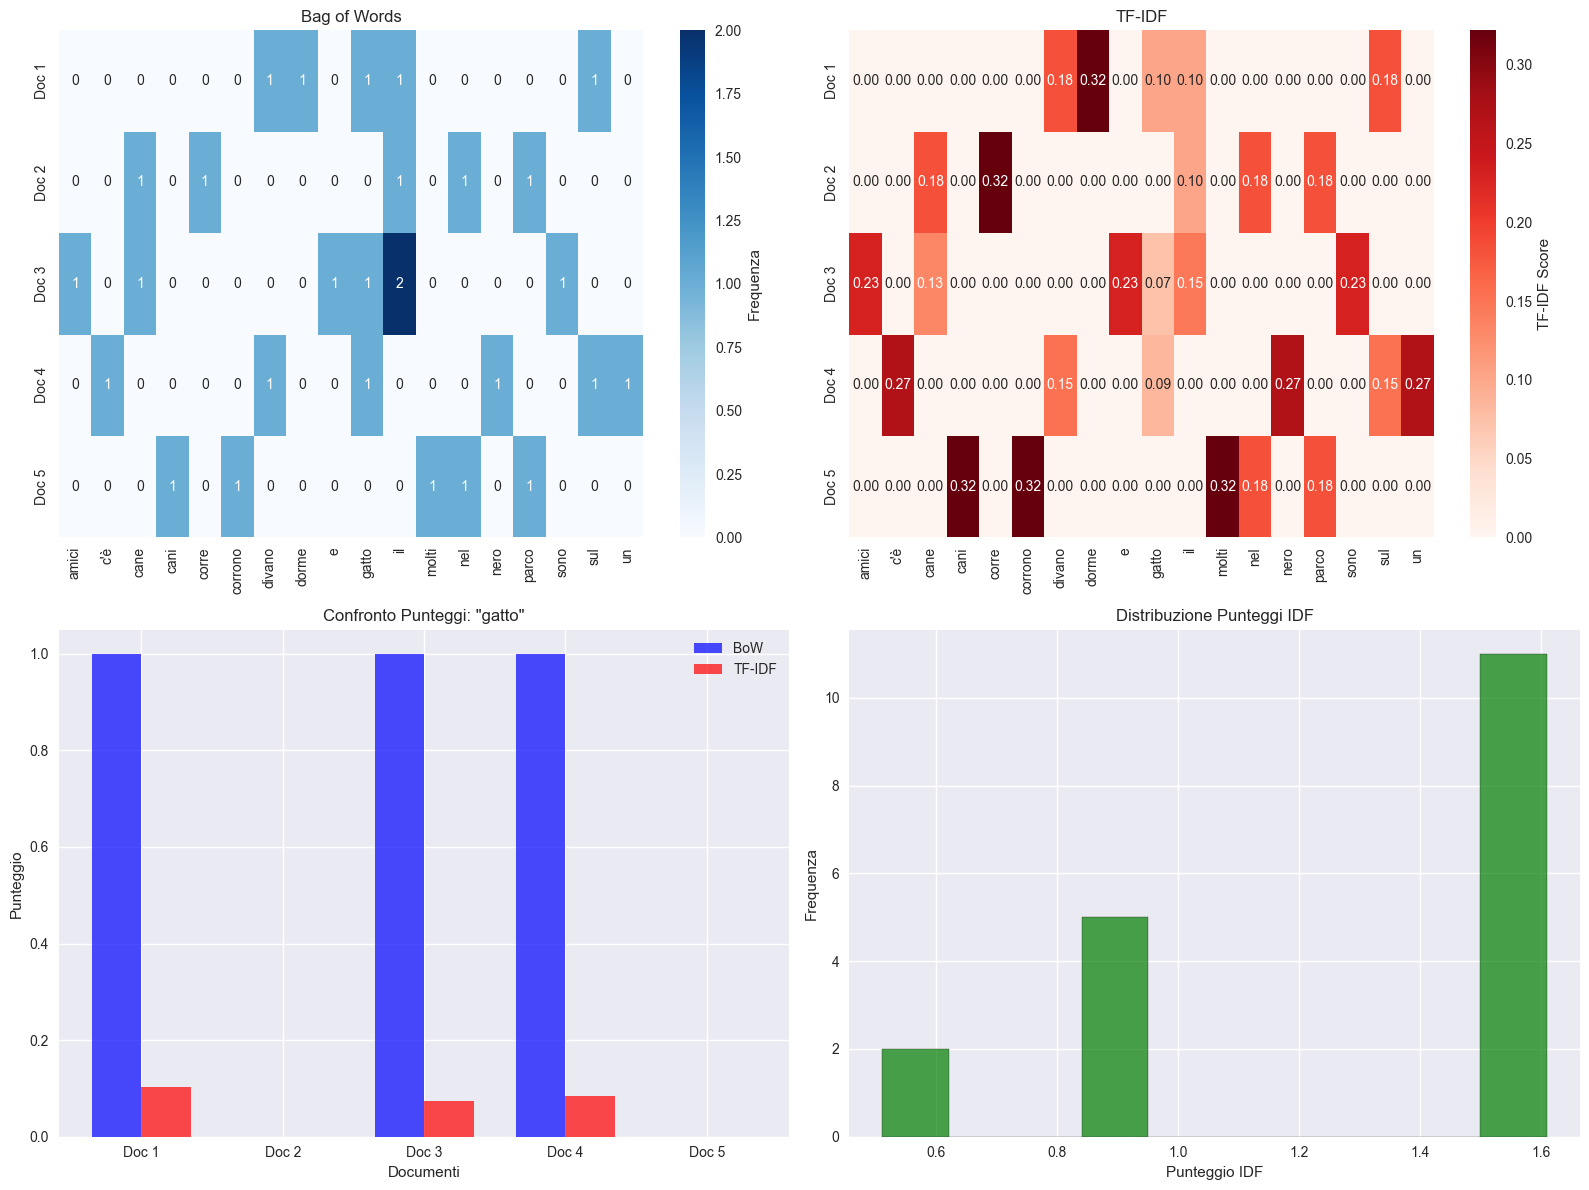


🔍 CONFRONTO SIMILARITÀ:

Similarità Doc 1 vs Doc 4 (entrambi parlano di gatti):
   BoW: 0.548
   TF-IDF: 0.284

Similarità Doc 2 vs Doc 5 (entrambi parlano di cani nel parco):
   BoW: 0.400
   TF-IDF: 0.236

💡 VANTAGGI TF-IDF:
✅ Riduce l'importanza di parole comuni
✅ Evidenzia parole distintive
✅ Migliore per ricerca e classificazione
✅ Normalizza per lunghezza documento

❌ LIMITI TF-IDF:
❌ Ancora ignora l'ordine delle parole
❌ Non cattura sinonimi
❌ Vettori ancora sparsi
❌ Non comprende il contesto


In [5]:
# Implementiamo TF-IDF da zero
class TFIDF:
    def __init__(self):
        self.vocabolario = {}
        self.idf_scores = {}
        self.dimensione_vocab = 0
    
    def calcola_tf(self, documento):
        """Calcola Term Frequency per un documento"""
        parole = documento.lower().split()
        tf = Counter(parole)
        
        # Normalizza per la lunghezza del documento
        lunghezza_doc = len(parole)
        for parola in tf:
            tf[parola] = tf[parola] / lunghezza_doc
        
        return tf
    
    def calcola_idf(self, documenti):
        """Calcola Inverse Document Frequency"""
        n_documenti = len(documenti)
        
        # Conta in quanti documenti appare ogni parola
        df = defaultdict(int)  # document frequency
        
        for doc in documenti:
            parole_uniche = set(doc.lower().split())
            for parola in parole_uniche:
                df[parola] += 1
        
        # Calcola IDF
        for parola, freq_doc in df.items():
            self.idf_scores[parola] = math.log(n_documenti / freq_doc)
        
        # Costruisci vocabolario
        for i, parola in enumerate(sorted(df.keys())):
            self.vocabolario[parola] = i
        
        self.dimensione_vocab = len(self.vocabolario)
    
    def documento_to_tfidf(self, documento):
        """Converte documento in vettore TF-IDF"""
        tf = self.calcola_tf(documento)
        vettore = np.zeros(self.dimensione_vocab)
        
        for parola, tf_score in tf.items():
            if parola in self.vocabolario:
                indice = self.vocabolario[parola]
                idf_score = self.idf_scores[parola]
                vettore[indice] = tf_score * idf_score
        
        return vettore
    
    def fit_transform(self, documenti):
        """Addestra e trasforma i documenti"""
        self.calcola_idf(documenti)
        
        matrice = []
        for doc in documenti:
            vettore = self.documento_to_tfidf(doc)
            matrice.append(vettore)
        
        return np.array(matrice)

# Test TF-IDF
print("📊 TF-IDF - IMPLEMENTAZIONE DA ZERO\n")

# Usiamo gli stessi documenti
tfidf = TFIDF()
matrice_tfidf = tfidf.fit_transform(documenti_esempio)

print(f"📚 Vocabolario TF-IDF: {tfidf.dimensione_vocab} parole")

# Mostriamo i punteggi IDF
print("\n🔢 PUNTEGGI IDF (Inverse Document Frequency):")
idf_ordinati = sorted(tfidf.idf_scores.items(), key=lambda x: x[1], reverse=True)
for parola, idf in idf_ordinati:
    print(f"   '{parola}': {idf:.3f}")

print("\n💡 INTERPRETAZIONE IDF:")
print("   • Punteggio ALTO = parola rara (appare in pochi documenti)")
print("   • Punteggio BASSO = parola comune (appare in molti documenti)")
print("   • 'il' ha IDF basso perché appare ovunque")
print("   • 'nero' ha IDF alto perché appare solo in un documento")

# Confronto BoW vs TF-IDF
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# DataFrame per TF-IDF
df_tfidf = pd.DataFrame(matrice_tfidf, 
                        columns=list(tfidf.vocabolario.keys()),
                        index=[f"Doc {i+1}" for i in range(len(documenti_esempio))])

# Heatmap BoW
sns.heatmap(df_bow, annot=True, cmap='Blues', ax=axes[0,0], 
            cbar_kws={'label': 'Frequenza'})
axes[0,0].set_title('Bag of Words')

# Heatmap TF-IDF
sns.heatmap(df_tfidf, annot=True, fmt='.2f', cmap='Reds', ax=axes[0,1],
            cbar_kws={'label': 'TF-IDF Score'})
axes[0,1].set_title('TF-IDF')

# Confronto punteggi per una parola specifica
parola_esempio = 'gatto'
if parola_esempio in bow.vocabolario and parola_esempio in tfidf.vocabolario:
    idx_bow = bow.vocabolario[parola_esempio]
    idx_tfidf = tfidf.vocabolario[parola_esempio]
    
    bow_scores = matrice_bow[:, idx_bow]
    tfidf_scores = matrice_tfidf[:, idx_tfidf]
    
    x = np.arange(len(documenti_esempio))
    width = 0.35
    
    axes[1,0].bar(x - width/2, bow_scores, width, label='BoW', alpha=0.7, color='blue')
    axes[1,0].bar(x + width/2, tfidf_scores, width, label='TF-IDF', alpha=0.7, color='red')
    axes[1,0].set_title(f'Confronto Punteggi: "{parola_esempio}"')
    axes[1,0].set_xlabel('Documenti')
    axes[1,0].set_ylabel('Punteggio')
    axes[1,0].set_xticks(x)
    axes[1,0].set_xticklabels([f'Doc {i+1}' for i in range(len(documenti_esempio))])
    axes[1,0].legend()

# Distribuzione punteggi IDF
idf_values = list(tfidf.idf_scores.values())
axes[1,1].hist(idf_values, bins=10, alpha=0.7, color='green', edgecolor='black')
axes[1,1].set_title('Distribuzione Punteggi IDF')
axes[1,1].set_xlabel('Punteggio IDF')
axes[1,1].set_ylabel('Frequenza')

plt.tight_layout()
plt.show()

# Confronto similarità
print("\n🔍 CONFRONTO SIMILARITÀ:")
sim_bow = cosine_similarity(matrice_bow)
sim_tfidf = cosine_similarity(matrice_tfidf)

print("\nSimilarità Doc 1 vs Doc 4 (entrambi parlano di gatti):")
print(f"   BoW: {sim_bow[0][3]:.3f}")
print(f"   TF-IDF: {sim_tfidf[0][3]:.3f}")

print("\nSimilarità Doc 2 vs Doc 5 (entrambi parlano di cani nel parco):")
print(f"   BoW: {sim_bow[1][4]:.3f}")
print(f"   TF-IDF: {sim_tfidf[1][4]:.3f}")

print("\n💡 VANTAGGI TF-IDF:")
print("✅ Riduce l'importanza di parole comuni")
print("✅ Evidenzia parole distintive")
print("✅ Migliore per ricerca e classificazione")
print("✅ Normalizza per lunghezza documento")

print("\n❌ LIMITI TF-IDF:")
print("❌ Ancora ignora l'ordine delle parole")
print("❌ Non cattura sinonimi")
print("❌ Vettori ancora sparsi")
print("❌ Non comprende il contesto")

## 🧠 Word2Vec - Embeddings Intelligenti

**Word2Vec** rappresenta un salto qualitativo: impara rappresentazioni dense che catturano relazioni semantiche:

🧠 WORD2VEC - EMBEDDINGS INTELLIGENTI

📚 CORPUS ESTESO: 20 frasi
🔤 FRASI TOKENIZZATE: 20 frasi
Esempio: ['il', 'gatto', 'dorme', 'sul', 'divano', 'comodo']

🏋️ ADDESTRAMENTO WORD2VEC...
✅ Addestramento completato!
📊 Vocabolario: 74 parole
🔢 Dimensione embeddings: 50

🔍 ESPLORAZIONE EMBEDDINGS:
Parole nel vocabolario: ['i', 'è', 'il', 'sono', 'salute', 'la', 'gli', 'caldo', 'dormire', 'parco']...

🐱 Embedding di 'gatto':
   Dimensioni: (50,)
   Primi 10 valori: [-0.00472938  0.01024703 -0.01380215 -0.01265863  0.00420936 -0.02185506
  0.00403933  0.00697819  0.01552238 -0.01763817]

🔗 PAROLE PIÙ SIMILI A 'gatto':
   'divano': 0.399
   'le': 0.394
   'caldo': 0.371
   'la': 0.334
   'vivaci': 0.329

🧮 TEST ANALOGIE:
gatto : dorme = cane : ?
   in (0.331)
   fisica (0.303)
   ombra (0.204)

📊 VISUALIZZAZIONE EMBEDDINGS (PCA 2D):


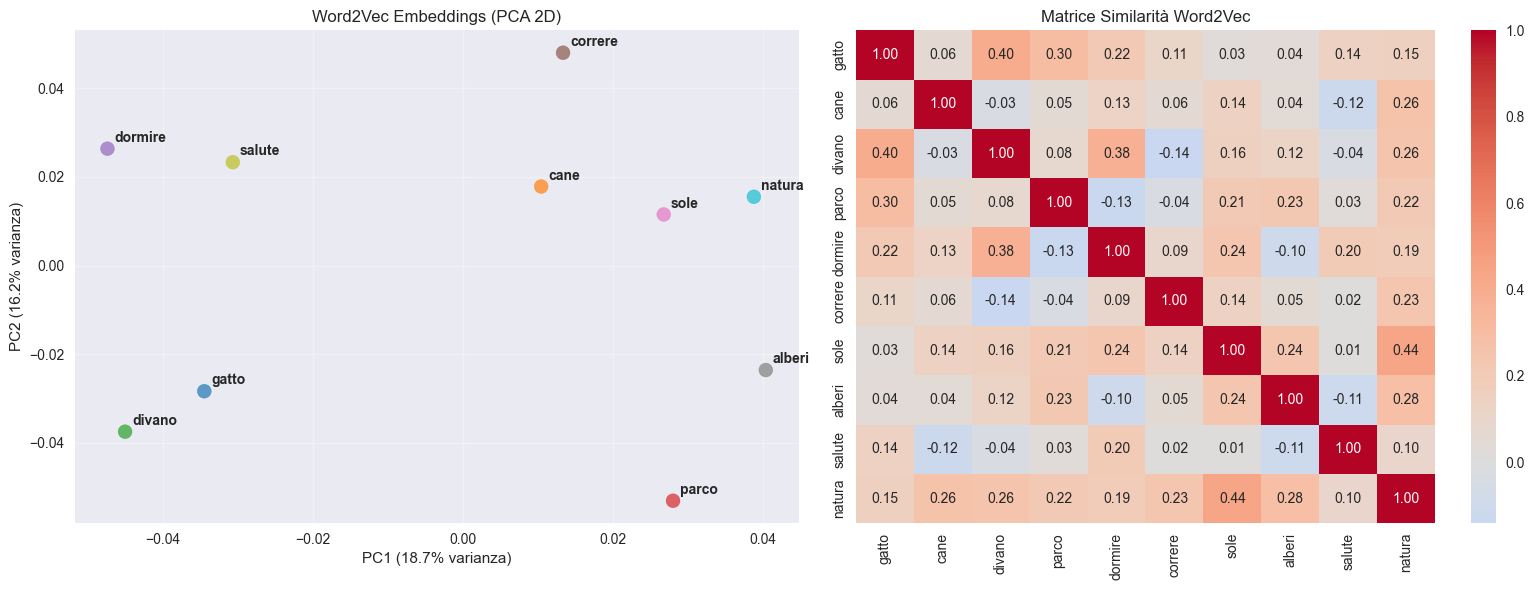

👀 OSSERVAZIONI:
   • Parole semanticamente simili sono vicine nello spazio
   • Gli embeddings catturano relazioni non evidenti in BoW/TF-IDF
   • La dimensionalità è molto più bassa ma più informativa

💡 VANTAGGI WORD2VEC:
✅ Cattura relazioni semantiche
✅ Embeddings densi (pochi zeri)
✅ Dimensionalità controllabile
✅ Supporta analogie
✅ Transfer learning possibile

❌ LIMITI WORD2VEC:
❌ Una rappresentazione per parola (no polisemia)
❌ Non gestisce parole fuori vocabolario
❌ Richiede grandi corpus per qualità
❌ Non considera contesto della frase


In [6]:

print("🧠 WORD2VEC - EMBEDDINGS INTELLIGENTI\n")

# Per questo esempio, creeremo un piccolo corpus e addestriamo Word2Vec
# In pratica, usereste modelli pre-addestrati su grandi corpus

# Corpus più grande per addestrare Word2Vec
corpus_esteso = [
    "il gatto dorme sul divano comodo",
    "il cane corre veloce nel parco verde",
    "i gatti amano dormire al sole caldo",
    "i cani giocano insieme nel parco",
    "il divano è molto comodo per dormire",
    "nel parco ci sono molti alberi verdi",
    "gli animali domestici sono fedeli compagni",
    "il sole splende caldo in giardino",
    "dormire è importante per la salute",
    "correre fa bene alla salute fisica",
    "i compagni fedeli sono preziosi",
    "il giardino verde è pieno di fiori",
    "gli alberi danno ombra fresca",
    "i fiori colorati profumano dolcemente",
    "la salute fisica è molto importante",
    "gli animali selvatici vivono liberi",
    "la natura è bella e selvaggia",
    "i colori della natura sono vivaci",
    "l'ombra fresca protegge dal caldo",
    "i profumi dolci attirano le api"
]

print(f"📚 CORPUS ESTESO: {len(corpus_esteso)} frasi")

# Prepariamo i dati per Word2Vec
frasi_tokenizzate = []
for frase in corpus_esteso:
    tokens = frase.lower().split()
    frasi_tokenizzate.append(tokens)


# Preparazione dei dati:
# CORPUS (frasi normali)
#       ↓
# TOKENIZZAZIONE (ogni frase viene divisa in parole/token)
#       ↓
# frasi_tokenizzate = lista di liste di token
#
# Esempio:
# "il gatto dorme sul divano"
#       ↓
# ["il", "gatto", "dorme", "sul", "divano"]
print(f"🔤 FRASI TOKENIZZATE: {len(frasi_tokenizzate)} frasi")
print("Esempio:", frasi_tokenizzate[0])

# Addestriamo Word2Vec
print("\n🏋️ ADDESTRAMENTO WORD2VEC...")
model_w2v = Word2Vec(
    sentences=frasi_tokenizzate,
    vector_size=50,      # Dimensione degli embeddings
    window=5,            # Finestra di contesto
    min_count=1,         # Frequenza minima parole
    workers=4,           # Thread paralleli
    sg=0,                # 0=CBOW, 1=Skip-gram
    epochs=100           # Numero di epoche
)

print("✅ Addestramento completato!")

# .wv (Word Vectors) contiene gli embedding delle parole appresi dal modello Word2Vec.
# key_to_index contiene il vocabolario e associa ogni parola a un indice numerico.
# len(...) conta quante parole sono presenti nel vocabolario.
print(f"📊 Vocabolario: {len(model_w2v.wv.key_to_index)} parole")

# .vector_size indica il numero di dimensioni di ogni vettore.
print(f"🔢 Dimensione embeddings: {model_w2v.wv.vector_size}")

# Esploriamo gli embeddings
print("\n🔍 ESPLORAZIONE EMBEDDINGS:")



#Non stiamo più facendo addestramento ma stiamo vedendo cosa abbiamo imparato
# Parole nel vocabolario
vocabolario_w2v = list(model_w2v.wv.key_to_index.keys())
print(f"Parole nel vocabolario: {vocabolario_w2v[:10]}...")

# Embedding di una parola specifica
parola_test = 'gatto'
if parola_test in model_w2v.wv:
    embedding_gatto = model_w2v.wv[parola_test]
    print(f"\n🐱 Embedding di '{parola_test}':")
    print(f"   Dimensioni: {embedding_gatto.shape}")
    print(f"   Primi 10 valori: {embedding_gatto[:10]}")
else:
    print(f"\n❌ La parola '{parola_test}' non è presente nel vocabolario.")
    print("   Non è possibile recuperare il suo embedding.")



# Chiediamo a Word2Vec quali parole hanno un embedding
# più simile a quello della parola scelta.
  # most_similar() confronta l'embedding della parola scelta
    # con gli embedding delle altre parole presenti nel vocabolario.
    # topn=5 indica che vogliamo ottenere le 5 parole più simili.
print(f"\n🔗 PAROLE PIÙ SIMILI A '{parola_test}':")
try:
    simili = model_w2v.wv.most_similar(parola_test, topn=5)
    for parola, similarita in simili:
        print(f"   '{parola}': {similarita:.3f}")
except KeyError:
    print(f"   '{parola_test}' non trovato nel vocabolario")

# Test analogie (se possibile con il nostro piccolo corpus)
# ============================================================
# TEST DELLE ANALOGIE TRA PAROLE
# ============================================================

print("\n🧮 TEST ANALOGIE:")

try:

    # Vogliamo verificare una relazione del tipo:
    #
    #     gatto : dorme = cane : ?
    #
    # In altre parole, chiediamo a Word2Vec di trovare
    # una parola che completi l'analogia.
    #
    # Per farlo, utilizziamo gli embedding delle parole
    # e una semplice operazione matematica sui loro vettori.

    analogia = model_w2v.wv.most_similar(

        # Le parole indicate come "positive" vengono aggiunte
        # nel calcolo del vettore risultante.
        positive=['cane', 'dorme'],

        # La parola "gatto" viene sottratta dal calcolo.
        negative=['gatto'],

        # Restituiamo le 3 parole più vicine
        # al vettore ottenuto dall'operazione.
        topn=3
    )

    # Stampiamo l'analogia che stiamo cercando di risolvere.
    print("gatto : dorme = cane : ?")

    # Per ogni risultato ottenuto:
    # - parola = parola candidata trovata da Word2Vec
    # - score = punteggio di similarità con il risultato dell'analogia
    for parola, score in analogia:

        # Stampiamo la parola e il relativo punteggio.
        # :.3f significa che il punteggio viene mostrato
        # con 3 cifre decimali.
        print(f"   {parola} ({score:.3f})")

except:

    # Se una delle parole non è presente nel vocabolario
    # oppure l'analogia non può essere calcolata,
    # evitiamo che il programma si interrompa.
    print("   Analogie non disponibili con questo corpus piccolo")




    
# Visualizzazione degli embeddings
print("\n📊 VISUALIZZAZIONE EMBEDDINGS (PCA 2D):")

# Selezioniamo alcune parole interessanti
parole_interesse = ['gatto', 'cane', 'divano', 'parco', 'dormire', 'correre', 
                   'sole', 'alberi', 'salute', 'natura']
parole_disponibili = [p for p in parole_interesse if p in model_w2v.wv]

if len(parole_disponibili) > 3:
    # Ottieni embeddings
    embeddings_viz = np.array([model_w2v.wv[parola] for parola in parole_disponibili])
    
    # Riduci dimensionalità con PCA
    pca = PCA(n_components=2)
    embeddings_2d = pca.fit_transform(embeddings_viz)
    
    # Visualizza
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    # Scatter plot
    scatter = ax1.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], 
                         s=100, alpha=0.7, c=range(len(parole_disponibili)), 
                         cmap='tab10')
    
    for i, parola in enumerate(parole_disponibili):
        ax1.annotate(parola, (embeddings_2d[i, 0], embeddings_2d[i, 1]),
                    xytext=(5, 5), textcoords='offset points',
                    fontsize=10, fontweight='bold')
    
    ax1.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} varianza)')
    ax1.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} varianza)')
    ax1.set_title('Word2Vec Embeddings (PCA 2D)')
    ax1.grid(True, alpha=0.3)
    
    # Matrice di similarità
    n_parole = len(parole_disponibili)
    matrice_sim = np.zeros((n_parole, n_parole))
    
    for i, parola1 in enumerate(parole_disponibili):
        for j, parola2 in enumerate(parole_disponibili):
            if i != j:
                sim = model_w2v.wv.similarity(parola1, parola2)
                matrice_sim[i, j] = sim
            else:
                matrice_sim[i, j] = 1.0
    
    sns.heatmap(matrice_sim, 
                xticklabels=parole_disponibili,
                yticklabels=parole_disponibili,
                annot=True, fmt='.2f', cmap='coolwarm',
                center=0, ax=ax2)
    ax2.set_title('Matrice Similarità Word2Vec')
    
    plt.tight_layout()
    plt.show()
    
    print("👀 OSSERVAZIONI:")
    print("   • Parole semanticamente simili sono vicine nello spazio")
    print("   • Gli embeddings catturano relazioni non evidenti in BoW/TF-IDF")
    print("   • La dimensionalità è molto più bassa ma più informativa")

print("\n💡 VANTAGGI WORD2VEC:")
print("✅ Cattura relazioni semantiche")
print("✅ Embeddings densi (pochi zeri)")
print("✅ Dimensionalità controllabile")
print("✅ Supporta analogie")
print("✅ Transfer learning possibile")

print("\n❌ LIMITI WORD2VEC:")
print("❌ Una rappresentazione per parola (no polisemia)")
print("❌ Non gestisce parole fuori vocabolario")
print("❌ Richiede grandi corpus per qualità")
print("❌ Non considera contesto della frase")

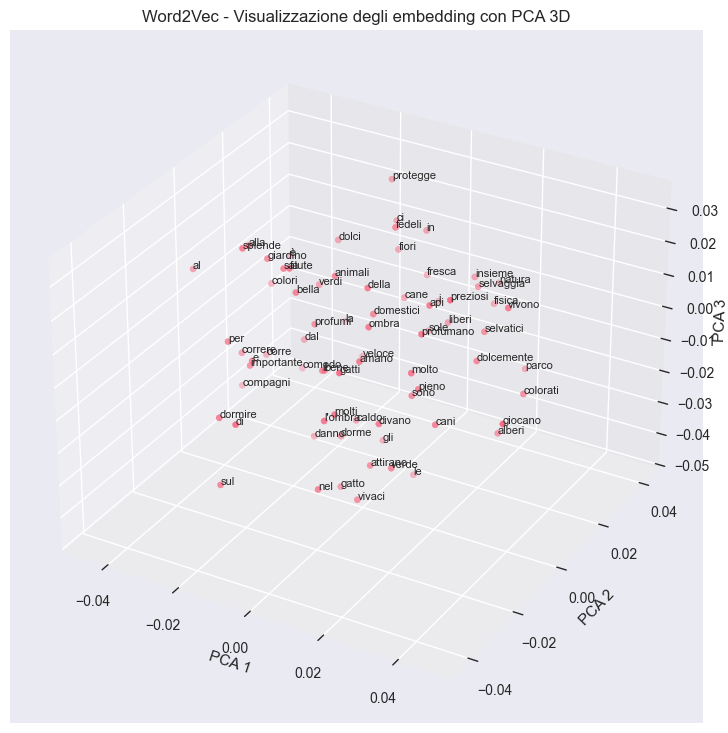

In [7]:
# ============================================================
# VISUALIZZAZIONE DEGLI EMBEDDING CON PCA 3D
# ============================================================

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Recuperiamo tutte le parole presenti nel vocabolario
parole = list(model_w2v.wv.key_to_index.keys())

# Recuperiamo l'embedding di ogni parola.
# Ogni parola è rappresentata da un vettore di 50 numeri.
vettori = [model_w2v.wv[parola] for parola in parole]

# Creiamo una PCA che riduce le 50 dimensioni
# degli embedding a sole 3 dimensioni.
pca = PCA(n_components=3)

# Trasformiamo i vettori originali da 50 dimensioni
# a 3 componenti principali.
vettori_3d = pca.fit_transform(vettori)

# Creiamo il grafico 3D
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# Disegniamo ogni parola come un punto nello spazio 3D
ax.scatter(
    vettori_3d[:, 0],
    vettori_3d[:, 1],
    vettori_3d[:, 2]
)

# Aggiungiamo il nome della parola vicino al punto
for i, parola in enumerate(parole):
    ax.text(
        vettori_3d[i, 0],
        vettori_3d[i, 1],
        vettori_3d[i, 2],
        parola,
        fontsize=8
    )

# Etichette degli assi
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_zlabel("PCA 3")

# Titolo
ax.set_title("Word2Vec - Visualizzazione degli embedding con PCA 3D")

plt.show()

## 🔍 Confronto Completo dei Metodi

Confrontiamo tutti i metodi su un task pratico:

🔍 CONFRONTO COMPLETO: BoW vs TF-IDF vs Word2Vec

🎯 QUERY: 'gatto che dorme'
📚 DOCUMENTI DA CERCARE:
   1. il gatto dorme sul divano
   2. il cane corre nel parco
   3. il gatto e il cane sono amici
   4. sul divano c'è un gatto nero
   5. nel parco corrono molti cani

1️⃣ RICERCA CON BAG OF WORDS:
   1. Doc 1 (sim: 0.632): il gatto dorme sul divano
   2. Doc 4 (sim: 0.289): sul divano c'è un gatto nero
   3. Doc 3 (sim: 0.236): il gatto e il cane sono amici

2️⃣ RICERCA CON TF-IDF:
   1. Doc 1 (sim: 0.771): il gatto dorme sul divano
   2. Doc 4 (sim: 0.050): sul divano c'è un gatto nero
   3. Doc 3 (sim: 0.049): il gatto e il cane sono amici

3️⃣ RICERCA CON WORD2VEC:
   1. Doc 1 (sim: 0.739): il gatto dorme sul divano
   2. Doc 4 (sim: 0.549): sul divano c'è un gatto nero
   3. Doc 5 (sim: 0.409): nel parco corrono molti cani


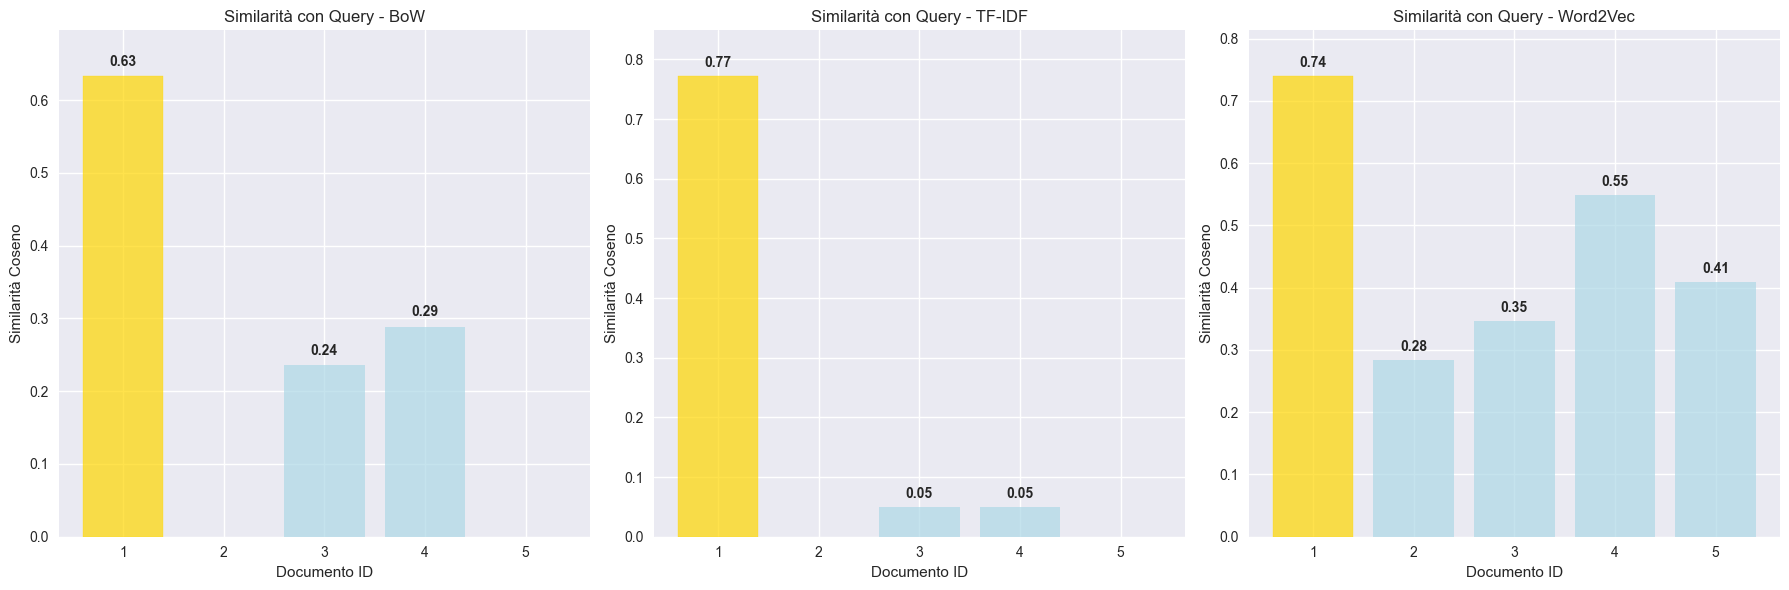


📊 TABELLA RIASSUNTIVA:
  Metodo Miglior Match                 Documento
     BoW Doc 1 (0.632) il gatto dorme sul divano
  TF-IDF Doc 1 (0.771) il gatto dorme sul divano
Word2Vec Doc 1 (0.739) il gatto dorme sul divano

💡 ANALISI RISULTATI:
• BoW: Trova corrispondenze esatte di parole
• TF-IDF: Bilancia frequenza e rarità
• Word2Vec: Cattura similarità semantica
• Ogni metodo ha i suoi punti di forza

🎯 QUANDO USARE COSA:
📊 BoW: Classificazione semplice, analisi frequenze
📈 TF-IDF: Ricerca documenti, classificazione testi
🧠 Word2Vec: Analisi semantica, raccomandazioni, AI avanzata


In [8]:
# ============================================================
# CONFRONTO: BoW vs TF-IDF vs Word2Vec
# ============================================================

# Usiamo la stessa query con tutti e tre i metodi
# per vedere quali documenti risultano più simili.

print("🔍 CONFRONTO COMPLETO: BoW vs TF-IDF vs Word2Vec\n")

#Quale documento è più simile a "gatto che dorme"?
query = "gatto che dorme"

print(f"🎯 QUERY: '{query}'")
print("📚 DOCUMENTI DA CERCARE:")

for i, doc in enumerate(documenti_esempio, 1):
    print(f"   {i}. {doc}")


# ============================================================
# 1️⃣ BAG OF WORDS
# ============================================================

print("\n1️⃣ RICERCA CON BAG OF WORDS:")

# Trasformiamo la query nello stesso vettore BoW
# utilizzato per rappresentare i documenti.
query_bow = bow.documento_to_vettore(query)

# Confrontiamo la query con tutti i documenti
# usando la similarità coseno.
sim_bow_query = cosine_similarity([query_bow], matrice_bow)[0]

# Creiamo una lista:
# (ID documento, similarità, testo)
risultati_bow = [
    (i + 1, sim, doc)
    for i, (sim, doc) in enumerate(
        zip(sim_bow_query, documenti_esempio)
    )
]

# Alla fine otteniamo una lista di risultati in cui ogni elemento contiene:
#
# (ID documento, similarità, testo del documento)
#
# Esempio:
#
# [
#     (1, 0.632, "il gatto dorme sul divano"),
#     (2, 0.100, "il cane corre nel parco"),
#     (3, 0.240, "i gatti amano dormire al sole")
# ]
#
# Successivamente questa lista verrà ordinata
# dal documento più simile al meno simile.

# Dal più simile al meno simile
risultati_bow.sort(key=lambda x: x[1], reverse=True)

for rank, (doc_id, similarita, doc) in enumerate(
    risultati_bow[:3], 1
):
    print(
        f"   {rank}. Doc {doc_id} "
        f"(sim: {similarita:.3f}): {doc}"
    )


# ============================================================
# 2️⃣ TF-IDF
# ============================================================

print("\n2️⃣ RICERCA CON TF-IDF:")

# Trasformiamo la query in un vettore TF-IDF.
query_tfidf = tfidf.documento_to_tfidf(query)

# Confrontiamo la query con tutti i documenti
# usando nuovamente la similarità coseno.
sim_tfidf_query = cosine_similarity(
    [query_tfidf],
    matrice_tfidf
)[0]

# Creiamo la lista dei risultati.
risultati_tfidf = [
    (i + 1, sim, doc)
    for i, (sim, doc) in enumerate(
        zip(sim_tfidf_query, documenti_esempio)
    )
]

# Dal più simile al meno simile
risultati_tfidf.sort(key=lambda x: x[1], reverse=True)

for rank, (doc_id, similarita, doc) in enumerate(
    risultati_tfidf[:3], 1
):
    print(
        f"   {rank}. Doc {doc_id} "
        f"(sim: {similarita:.3f}): {doc}"
    )


# ============================================================
# 3️⃣ WORD2VEC
# ============================================================

print("\n3️⃣ RICERCA CON WORD2VEC:")


# Word2Vec crea un vettore per ogni parola.
# Per rappresentare un intero documento,
# calcoliamo la media degli embedding delle sue parole.

def documento_to_w2v(documento, model):

    parole = documento.lower().split()
    embeddings = []

    for parola in parole:

        # Consideriamo solo le parole presenti
        # nel vocabolario di Word2Vec.
        if parola in model.wv:
            embeddings.append(model.wv[parola])

    # Un documento viene rappresentato
    # dalla media dei suoi embedding.
    if embeddings:
        return np.mean(embeddings, axis=0)

    # Se nessuna parola è presente nel vocabolario,
    # restituiamo un vettore di zeri.
    else:
        return np.zeros(model.wv.vector_size)


# Trasformiamo la query in un unico vettore Word2Vec.
query_w2v = documento_to_w2v(query, model_w2v)

# Trasformiamo tutti i documenti in vettori Word2Vec.
docs_w2v = [
    documento_to_w2v(doc, model_w2v)
    for doc in documenti_esempio
]


# Confrontiamo il vettore della query
# con i vettori dei documenti.
sim_w2v_query = cosine_similarity(
    [query_w2v],
    docs_w2v
)[0]

# Creiamo la lista dei risultati.
risultati_w2v = [
    (i + 1, sim, doc)
    for i, (sim, doc) in enumerate(
        zip(sim_w2v_query, documenti_esempio)
    )
]

# Dal più simile al meno simile
risultati_w2v.sort(key=lambda x: x[1], reverse=True)

for rank, (doc_id, similarita, doc) in enumerate(
    risultati_w2v[:3], 1
):
    print(
        f"   {rank}. Doc {doc_id} "
        f"(sim: {similarita:.3f}): {doc}"
    )


# ============================================================
# VISUALIZZAZIONE COMPARATIVA
# ============================================================

# Confrontiamo graficamente i risultati dei tre metodi.

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

metodi = ['BoW', 'TF-IDF', 'Word2Vec']

risultati_tutti = [
    risultati_bow,
    risultati_tfidf,
    risultati_w2v
]

for i, (metodo, risultati) in enumerate(
    zip(metodi, risultati_tutti)
):

    # Recuperiamo ID dei documenti e valori di similarità.
    doc_ids = [r[0] for r in risultati]
    similarita = [r[1] for r in risultati]

    # Una barra = un documento.
    # L'altezza indica la similarità con la query.
    bars = axes[i].bar(
        doc_ids,
        similarita,
        alpha=0.7,
        color=[
            'gold' if j == 0 else 'lightblue'
            for j in range(len(doc_ids))
        ]
    )

    axes[i].set_title(
        f'Similarità con Query - {metodo}'
    )
    axes[i].set_xlabel('Documento ID')
    axes[i].set_ylabel('Similarità Coseno')

    axes[i].set_ylim(
        0,
        max(similarita) * 1.1
        if max(similarita) > 0
        else 1
    )

    # Evidenziamo il documento con la similarità maggiore.
    best_idx = np.argmax(similarita)
    bars[best_idx].set_color('gold')

    # Mostriamo il valore sopra ogni barra.
    for bar, sim in zip(bars, similarita):

        if sim > 0:
            axes[i].text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.01,
                f'{sim:.2f}',
                ha='center',
                va='bottom',
                fontweight='bold'
            )

plt.tight_layout()
plt.show()


# ============================================================
# TABELLA RIASSUNTIVA
# ============================================================

print("\n📊 TABELLA RIASSUNTIVA:")

# Per ogni metodo mostriamo:
# - il documento migliore
# - il suo punteggio
# - il testo del documento

df_confronto = pd.DataFrame({
    'Metodo': ['BoW', 'TF-IDF', 'Word2Vec'],

    'Miglior Match': [
        f"Doc {risultati_bow[0][0]} "
        f"({risultati_bow[0][1]:.3f})",

        f"Doc {risultati_tfidf[0][0]} "
        f"({risultati_tfidf[0][1]:.3f})",

        f"Doc {risultati_w2v[0][0]} "
        f"({risultati_w2v[0][1]:.3f})"
    ],

    'Documento': [
        risultati_bow[0][2],
        risultati_tfidf[0][2],
        risultati_w2v[0][2]
    ]
})

print(df_confronto.to_string(index=False))


# ============================================================
# CONCLUSIONE
# ============================================================

print("\n💡 ANALISI RISULTATI:")

print("• BoW: Trova corrispondenze esatte di parole")
print("• TF-IDF: Bilancia frequenza e rarità")
print("• Word2Vec: Cattura similarità semantica")
print("• Ogni metodo ha i suoi punti di forza")


print("\n🎯 QUANDO USARE COSA:")

print("📊 BoW: Classificazione semplice, analisi frequenze")
print("📈 TF-IDF: Ricerca documenti, classificazione testi")
print("🧠 Word2Vec: Analisi semantica, raccomandazioni, AI avanzata")